# Síntese

**Pergunta do projeto:** o mercado cervejeiro brasileiro está encolhendo em volume, mas para onde o valor está migrando e quem o captura?

**Hipótese:** o setor vive uma premiumização concentrada. O puro malte cresce enquanto o total cai, e esse crescimento está ligado à concentração da produção em poucas cervejarias.

Este notebook liga os dois eixos da análise (concentração, notebook 03, e tendências, notebook 04), apresenta os três achados principais e dá o veredito da hipótese.

## Preparação

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")

pd.options.display.float_format = "{:,.2f}".format

PASTA_SAIDA = Path("../data/processed")
PASTA_FIGURAS = Path("../docs/figuras")

TOTAL_2025 = 15_688_083_191.69

COR_SERIE = "#2a78d6"
COR_SEGUNDA = "#eb6834"
COR_NEUTRA = "#b9b8b1"
COR_TEXTO = "#0b0b0b"
COR_TEXTO_2 = "#52514e"
COR_GRADE = "#e4e3df"
COR_FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO,
    "axes.facecolor": COR_FUNDO,
    "axes.edgecolor": COR_GRADE,
    "axes.labelcolor": COR_TEXTO_2,
    "xtick.color": COR_TEXTO_2,
    "ytick.color": COR_TEXTO_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.8,
    "font.size": 10,
})

## 1. Quem produz o puro malte?

O Anuário não traz dados por cervejaria, mas a Tabela 19 permite calcular um **limite lógico**. Se as cervejarias fora do grupo das maiores produzissem só puro malte, cobririam no máximo o volume total delas. O que faltar para chegar aos 4,58 bilhões de litros de puro malte vem, necessariamente, das maiores.

In [2]:
conc_2025 = pd.read_csv(PASTA_SAIDA / "tabela_19_concentracao_2025.csv")
malte_2025 = pd.read_csv(PASTA_SAIDA / "tabela_20_puro_malte_2025.csv")
malte_2024 = pd.read_csv(PASTA_SAIDA / "puro_malte_2024.csv")

puro_malte_2025 = malte_2025.loc[malte_2025["categoria"].str.startswith("Cerveja Puro Malte"), "volume_litros"].iloc[0]
puro_malte_2024 = malte_2024.loc[malte_2024["categoria"].str.startswith("Cerveja Puro Malte"), "volume_litros"].iloc[0]

limites = []
for pct in [1, 2, 3, 4, 5]:
    volume_maiores = conc_2025.loc[conc_2025["pct_cervejarias"] == pct, "volume_litros"].iloc[0]
    volume_demais = TOTAL_2025 - volume_maiores
    minimo_das_maiores = max(puro_malte_2025 - volume_demais, 0)
    limites.append({
        "maiores_pct": pct,
        "volume_das_demais_litros": volume_demais,
        "puro_malte_minimo_das_maiores_pct": minimo_das_maiores / puro_malte_2025 * 100,
    })

limites = pd.DataFrame(limites)
limites

,maiores_pct,volume_das_demais_litros,puro_malte_minimo_das_maiores_pct
0,1,"9,021,889,356.31",0.00
1,2,"4,449,315,068.91",2.86
2,3,"1,714,766,123.68",62.56
3,4,"537,767,991.12",88.26
4,5,"216,339,251.99",95.28


In [3]:
volume_95pct_menores = limites.loc[limites["maiores_pct"] == 5, "volume_das_demais_litros"].iloc[0]
crescimento_puro_malte = puro_malte_2025 - puro_malte_2024
crescimento_minimo_das_maiores = crescimento_puro_malte - volume_95pct_menores

print(f"Crescimento do puro malte (base original): {crescimento_puro_malte / 1e6:,.0f} milhões de L")
print(f"Volume total das 95% menores em 2025: {volume_95pct_menores / 1e6:,.0f} milhões de L")
print(f"Parte do crescimento que veio, no mínimo, das 5% maiores: {crescimento_minimo_das_maiores / crescimento_puro_malte:.0%}")

Crescimento do puro malte (base original): 795 milhões de L
Volume total das 95% menores em 2025: 216 milhões de L
Parte do crescimento que veio, no mínimo, das 5% maiores: 73%


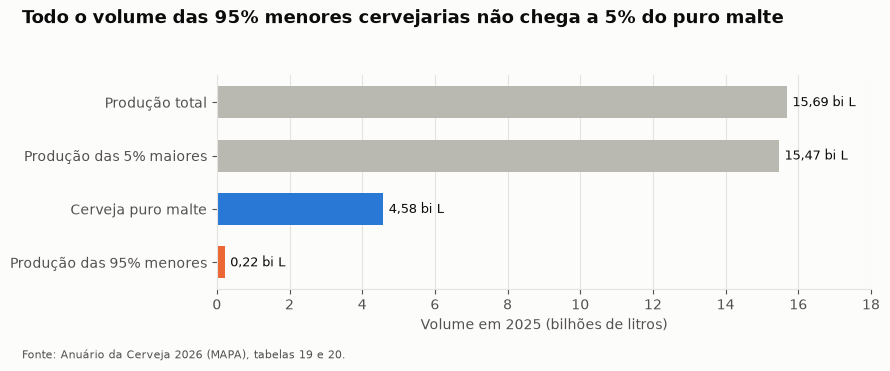

In [4]:
barras = pd.Series({
    "Produção total": TOTAL_2025,
    "Produção das 5% maiores": TOTAL_2025 - volume_95pct_menores,
    "Cerveja puro malte": puro_malte_2025,
    "Produção das 95% menores": volume_95pct_menores,
}) / 1e9
cores = [COR_NEUTRA, COR_NEUTRA, COR_SERIE, COR_SEGUNDA]

fig, ax = plt.subplots(figsize=(9, 3.6))
posicoes = range(len(barras))
ax.barh(list(posicoes), barras, color=cores, height=0.6)

for posicao, valor in zip(posicoes, barras):
    ax.text(valor + 0.15, posicao, f"{valor:,.2f} bi L".replace(".", ","), va="center", fontsize=9, color=COR_TEXTO)

ax.set_yticks(list(posicoes), barras.index)
ax.set_ylim(len(barras) - 0.5, -0.5)
ax.set_xlim(0, 18)
ax.set_xlabel("Volume em 2025 (bilhões de litros)")
ax.grid(axis="y", visible=False)

fig.suptitle(
    "Todo o volume das 95% menores cervejarias não chega a 5% do puro malte",
    x=0.03, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold",
)
fig.text(0.03, 0.01, "Fonte: Anuário da Cerveja 2026 (MAPA), tabelas 19 e 20.", fontsize=8, color=COR_TEXTO_2)
fig.tight_layout(rect=(0, 0.04, 1, 0.93))
fig.savefig(PASTA_FIGURAS / "puro_malte_origem.png", dpi=150)
plt.show()

## 2. Três achados

**1. A premiumização é real, mas menor do que o Anuário sugere.** A participação do puro malte no volume subiu de **24,7% para 29,2%** em um ano. O crescimento de 21% publicado é um teto: ele foi calculado sobre o total de 2024 antes da revisão do MAPA, e o crescimento mais provável é de cerca de 8%.

**2. A premiumização é das grandes cervejarias, não das artesanais.** As 95% menores cervejarias produziram, somadas, **0,22 bilhão de litros** em 2025, menos de 5% do puro malte. Pelo menos 95% do puro malte vem das 5% maiores. Os estilos artesanais ficaram estáveis ou em queda (IPA −0,8%, Malzbier −13%).

**3. Números oficiais precisam ser conferidos antes de virar conclusão.** O salto de **251%** na importação de cerveja em 2025 vem de uma única declaração aduaneira, com 19,4 milhões de litros registrados para 21 toneladas. Corrigida, a importação ficou estável. No total, o projeto registrou 14 inconsistências nas fontes.

## 3. Veredito: a hipótese se sustenta em parte

| Parte da hipótese | Resultado |
| --- | --- |
| O puro malte ganha espaço | **Sustenta-se.** Participação de 24,7% para 29,2%, com crescimento de tamanho incerto (de cerca de 8% a 21%) |
| A premiumização é concentrada | **Sustenta-se.** Pelo menos 95% do puro malte vem das 5% maiores cervejarias |
| A concentração está aumentando | **Não se sustenta.** A fatia do 1% maior caiu em qualquer cenário da revisão de 2024 |
| O mercado está encolhendo | **Indeterminado.** A produção caiu 8,85% sobre o total revisado de 2024, mas cresceu 2,2% sobre o original |
| Insumos e emprego acompanham | **Não se sustenta.** A importação de malte caiu 12,5% e o emprego, 2,6%, sem relação mensurável com o puro malte |

**Formulação revisada:** o mercado cervejeiro brasileiro vive uma premiumização liderada pelas grandes cervejarias, sem aumento da concentração e sobre um volume total cuja direção não se pode afirmar com os dados publicados.

## 4. Limitações

- **Volume, não valor.** A pergunta do projeto fala em valor, mas o Anuário só informa volumes. Sem preços ao consumidor por tipo de cerveja, o projeto mede para onde o **volume** migra, não o valor.
- **Dois anos de produção por tipo**, com bases diferentes para 2024 dentro do próprio Anuário 2026.
- **Sem dados por empresa.** O projeto mostra que as maiores produzem o puro malte, mas não identifica quais. Nenhuma marca é citada.
- **O índice de Gini é um limite inferior**, calculado com seis pontos da curva de concentração.
- **O número de cervejarias declarantes não é publicado**; as estimativas por cervejaria usam as 1.954 registradas.

## 5. O que eu faria com mais dados

- **Séries históricas por tipo de cerveja**, com uma base única de declarações, que poderiam ser pedidas ao MAPA pela Lei de Acesso à Informação.
- **Microdados anonimizados da declaração anual**, para calcular o Gini real e a participação do puro malte por porte de cervejaria.
- **Preços ao consumidor por segmento**, para responder à pergunta sobre valor, e não só sobre volume.